# Data exploration

Label statistics only on train/validation; test is untouched except for sizes and text lengths.

In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt
from art_nlp.data import SPLITS, load_split

data = {s: load_split(s) for s in SPLITS}
{s: len(d) for s, d in data.items()}

/Users/marvin/VSCode/nlp-hs26-art/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'train': 16801, 'validation': 1000, 'test': 1532}

## Examples

In [2]:
for ex in data['train'][:3]:
    print(ex.obs1, '|', ex.hyps, '|', ex.obs2, '| label', ex.label)

A baby panda was lost in the woods. | ('He was never lost.', 'All the people from the zoo looked for him.') | He was reunited with his parents, who also lived at the zoo. | label 1
A bank teller told me to rob the bank where she worked. | ('The mountain told me when no one would be there.', 'The teller told me when no one would be there.') | We split the money equally. | label 1
A bee was buzzing around my head. | ('It was because of the honey in my hair.', 'It was because of the blood in my stool.') | I didn't bother to explain the situation. | label 0


## Label balance (train, validation)

In [3]:
pd.DataFrame({s: pd.Series([e.label for e in data[s]]).value_counts(normalize=True) for s in ('train', 'validation')})

,train,validation
0,0.503601,0.508
1,0.496399,0.492


## Text lengths (rough regex tokens)

In [4]:
tok = lambda t: re.findall(r"\w+|[^\w\s]", t.lower())
rows = [dict(split=s, obs1=len(tok(e.obs1)), obs2=len(tok(e.obs2)), hyp=len(tok(h)))
        for s, d in data.items() for e in d for h in e.hyps]
lengths = pd.DataFrame(rows)
lengths.groupby('split').describe(percentiles=[.5, .99]).T.round(1)

split         test    train  validation
obs1 count  3064.0  33602.0      2000.0
     mean      9.3      9.4         9.6
     std       2.8      2.7         2.8
     min       4.0      3.0         4.0
     50%       9.0      9.0         9.0
     99%      16.0     16.0        16.0
     max      17.0     21.0        18.0
obs2 count  3064.0  33602.0      2000.0
     mean     10.7     10.7        10.7
     std       3.1      3.0         3.0
     min       3.0      3.0         3.0
     50%      11.0     11.0        11.0
     99%      17.0     17.0        17.0
     max      20.0     23.0        19.0
hyp  count  3064.0  33602.0      2000.0
     mean     10.0      9.8         9.9
     std       3.4      3.3         3.4
     min       3.0      1.0         4.0
     50%      10.0      9.0         9.0
     99%      21.0     21.0        22.0
     max      28.0     35.0        36.0

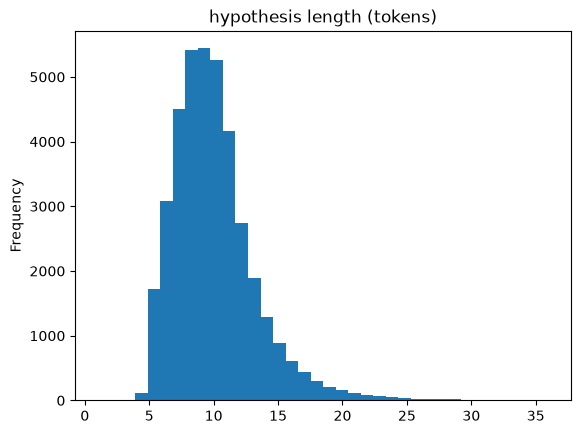

In [5]:
lengths.hyp.plot.hist(bins=36, title='hypothesis length (tokens)'); plt.show()

## How different are the two hypotheses?

Size of the symmetric difference of their word sets (label-free).

In [6]:
diff = pd.DataFrame([dict(split=s, words=len(set(tok(e.hyps[0])) ^ set(tok(e.hyps[1]))))
                     for s, d in data.items() for e in d])
diff.groupby('split').words.describe().round(1)

,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
test,1532.0,12.9,5.0,0.0,10.0,13.0,16.0,32.0
train,16801.0,5.1,3.8,0.0,2.0,4.0,6.0,33.0
validation,1000.0,4.8,3.6,0.0,2.0,4.0,6.0,22.0


Train/validation pairs are minimal edits (median ~4 differing words); test pairs differ much more. Validation accuracy may therefore not transfer one-to-one to test.

## Overlap of observation pairs between splits

In [7]:
pairs = {s: {(e.obs1, e.obs2) for e in d} for s, d in data.items()}
{f'{a}&{b}': len(pairs[a] & pairs[b]) for a, b in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]}

{'train&validation': 0, 'train&test': 0, 'validation&test': 0}

## Length heuristic (train, validation)

Accuracy of always picking the shorter hypothesis: a trivial baseline to beat.

In [8]:
{s: round(sum((len(tok(e.hyps[0])) > len(tok(e.hyps[1]))) == e.label for e in data[s]) / len(data[s]), 3)
 for s in ('train', 'validation')}

{'train': 0.546, 'validation': 0.542}